In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report

2026-03-31 10:06:27.639737: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774951587.861777      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774951587.925119      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774951588.470937      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774951588.470980      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774951588.470982      23 computation_placer.cc:177] computation placer alr

In [2]:
base_dir = '/kaggle/input/datasets/ibibekkumar/autism-dataset/Autism Dataset'

train_dir = os.path.join(base_dir, 'train')
valid_dir = os.path.join(base_dir, 'valid')
test_dir  = os.path.join(base_dir, 'test')

In [3]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    train_dir, target_size=(224,224), batch_size=32, class_mode='binary'
)

valid_data = val_test_datagen.flow_from_directory(
    valid_dir, target_size=(224,224), batch_size=32, class_mode='binary'
)

test_data = val_test_datagen.flow_from_directory(
    test_dir, target_size=(224,224), batch_size=32,
    class_mode='binary', shuffle=False
)

Found 2386 images belonging to 2 classes.
Found 254 images belonging to 2 classes.
Found 300 images belonging to 2 classes.


In [4]:
def build_resnet_model():
    base_model = ResNet50V2(
        weights='imagenet',
        include_top=False,
        input_shape=(224,224,3)
    )

    base_model.trainable = False  # Freeze initially

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(1, activation='sigmoid')(x)

    return Model(inputs=base_model.input, outputs=output)

tf.keras.backend.clear_session()
model = build_resnet_model()
model.summary()

I0000 00:00:1774951618.738649      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774951618.744672      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 56, 56,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 56, 56,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 58, 58,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 56, 56,    │          0 │ conv2_block1_0_c

 Total params: 24,097,793 (91.93 MB)

 Trainable params: 528,897 (2.02 MB)

 Non-trainable params: 23,568,896 (89.91 MB)

In [5]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7)
]

print("\n--- Phase 1: Training Top Layers ---")

history1 = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=20,
    callbacks=callbacks
)


--- Phase 1: Training Top Layers ---


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


I0000 00:00:1774951629.290415      90 service.cc:152] XLA service 0x7d385c002dc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774951629.290458      90 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774951629.290464      90 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774951630.999229      90 cuda_dnn.cc:529] Loaded cuDNN version 91002


 2/75 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.4141 - loss: 1.0356  

I0000 00:00:1774951636.814816      90 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


75/75 ━━━━━━━━━━━━━━━━━━━━ 64s 679ms/step - accuracy: 0.5475 - loss: 0.8393 - val_accuracy: 0.8150 - val_loss: 0.5097 - learning_rate: 1.0000e-04
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 404ms/step - accuracy: 0.6932 - loss: 0.6205 - val_accuracy: 0.8307 - val_loss: 0.4627 - learning_rate: 1.0000e-04
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 31s 406ms/step - accuracy: 0.7058 - loss: 0.6217 - val_accuracy: 0.8346 - val_loss: 0.4180 - learning_rate: 1.0000e-04
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 398ms/step - accuracy: 0.7182 - loss: 0.6016 - val_accuracy: 0.8425 - val_loss: 0.3968 - learning_rate: 1.0000e-04
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 399ms/step - accuracy: 0.7101 - loss: 0.5712 - val_accuracy: 0.8543 - val_loss: 0.3678 - learning_rate: 1.0000e-04
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 404ms/step - accuracy: 0.7407 - loss: 0.5635 - val_accuracy: 0.8543 - val_loss: 0.3662 - learning_rate: 1.0000e-04
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 402ms/step - accuracy: 0.72

In [6]:
# Unfreeze last 60 layers
for layer in model.layers[-60:]:
    if not isinstance(layer, BatchNormalization):
        layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("\n--- Phase 2: Fine-Tuning ---")

history2 = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=10,
    callbacks=callbacks
)


--- Phase 2: Fine-Tuning ---
Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 57s 538ms/step - accuracy: 0.7668 - loss: 0.5071 - val_accuracy: 0.8465 - val_loss: 0.3511 - learning_rate: 1.0000e-05
Epoch 2/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 393ms/step - accuracy: 0.7873 - loss: 0.4579 - val_accuracy: 0.8504 - val_loss: 0.3434 - learning_rate: 1.0000e-05
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 398ms/step - accuracy: 0.8079 - loss: 0.4372 - val_accuracy: 0.8701 - val_loss: 0.3189 - learning_rate: 1.0000e-05
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 392ms/step - accuracy: 0.8078 - loss: 0.4271 - val_accuracy: 0.8425 - val_loss: 0.3487 - learning_rate: 1.0000e-05
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 395ms/step - accuracy: 0.7870 - loss: 0.4352 - val_accuracy: 0.8661 - val_loss: 0.2916 - learning_rate: 1.0000e-05
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 392ms/step - accuracy: 0.8004 - loss: 0.4502 - val_accuracy: 0.8661 - val_loss: 0.2890 - learning_rate: 1.0000e-05
Epoch 7/10
75/75 ━━━━━━━━━━━

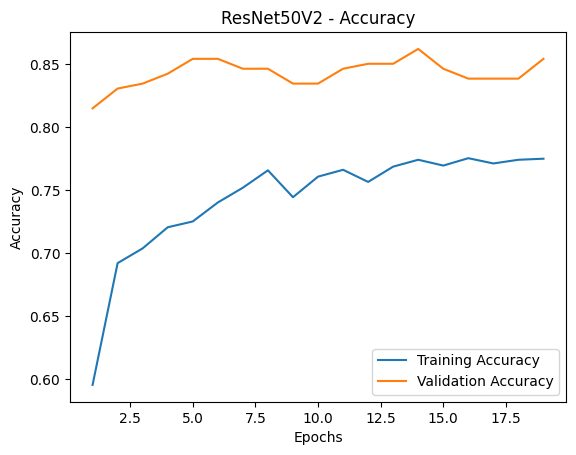

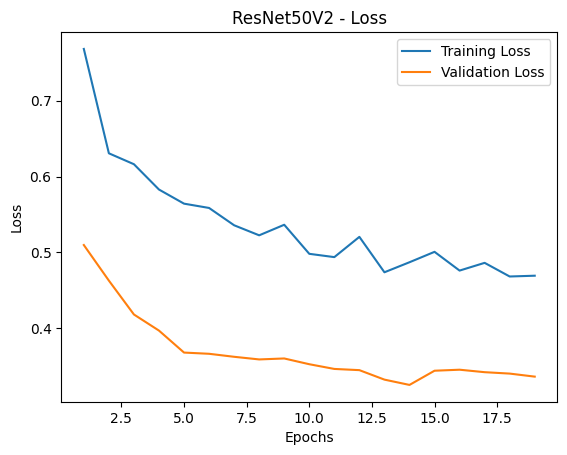

In [7]:
import matplotlib.pyplot as plt

acc = history1.history['accuracy']
val_acc = history1.history['val_accuracy']

loss = history1.history['loss']
val_loss = history1.history['val_loss']

epochs = range(1, len(acc) + 1)

# Accuracy Graph
plt.figure()
plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('ResNet50V2 - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss Graph
plt.figure()
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('ResNet50V2 - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [8]:
# ================================
# 2. GET PREDICTIONS
# ================================
test_data.reset()

predictions = model.predict(test_data)

y_pred = (predictions > 0.5).astype(int).flatten()
y_true = test_data.classes

labels = {v: k for k, v in test_data.class_indices.items()}


10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 817ms/step


In [9]:
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=list(labels.values())
))


Classification Report:

              precision    recall  f1-score   support

    Autistic       0.82      0.94      0.87       150
Non-Autistic       0.93      0.79      0.85       150

    accuracy                           0.86       300
   macro avg       0.87      0.86      0.86       300
weighted avg       0.87      0.86      0.86       300



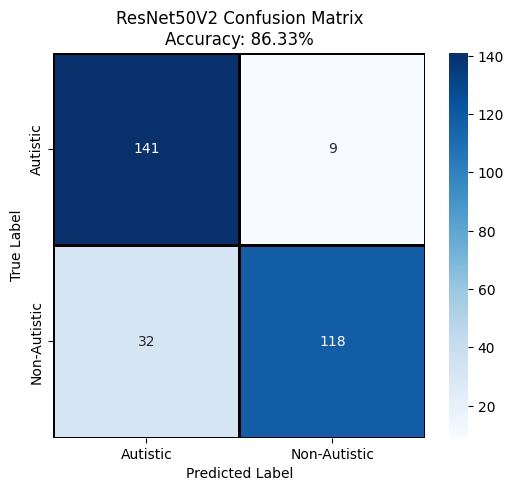

In [10]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(y_true, y_pred)
accuracy = np.mean(y_pred == y_true)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',   # 🔥 Blue color
    xticklabels=list(labels.values()),
    yticklabels=list(labels.values()),
    linewidths=1,
    linecolor='black'
)

plt.title(f'ResNet50V2 Confusion Matrix\nAccuracy: {accuracy*100:.2f}%')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

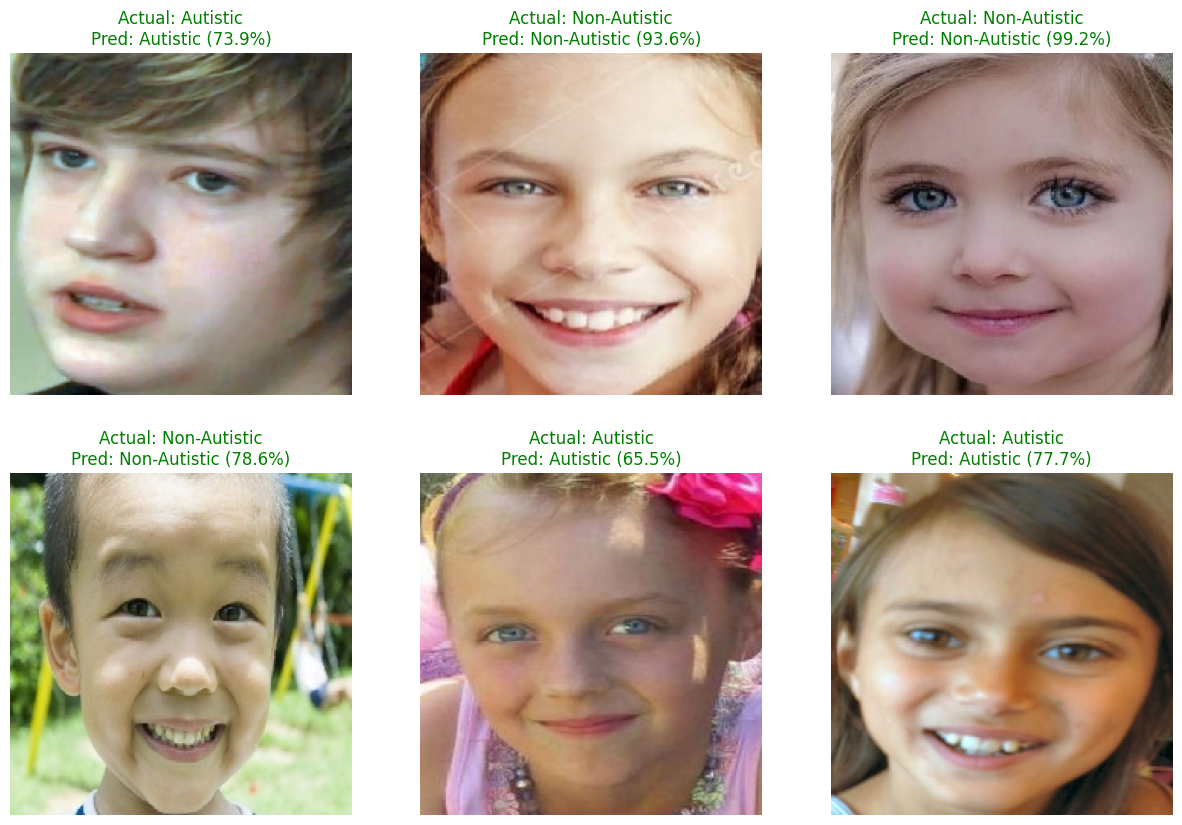

In [11]:
plt.figure(figsize=(15, 10))

for i in range(6):
    idx = np.random.randint(0, len(test_data.filenames))

    img_path = os.path.join(test_dir, test_data.filenames[idx])
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))

    plt.subplot(2, 3, i+1)
    plt.imshow(img)

    actual = labels[y_true[idx]]
    pred = labels[y_pred[idx]]

    conf = predictions[idx][0] if y_pred[idx] == 1 else 1 - predictions[idx][0]
    color = 'green' if actual == pred else 'red'

    plt.title(f"Actual: {actual}\nPred: {pred} ({conf*100:.1f}%)", color=color)
    plt.axis('off')

In [12]:
model.save('resnet50v2_autism_model.h5')